# 실습 4. 자가진화: AI가 데이터 처리 방법을 스스로 고쳐 성능 높이기

**상황**: 병원 전산에서 내려받은 자료는 모델이 바로 쓰기 어려운 경우가 많습니다. 이 실습의 자료에는 두 가지 문제가 있습니다.
- 키·몸무게가 `"170.2cm 72.5kg"`처럼 **글자 한 칸**에 적혀 있습니다.
- 혈압이 `"101 mmHg"`처럼 **글자**로 적혀 있습니다.

**자가진화(슬라이드 34~40)**: AI 에이전트가 고칠 방법을 **제안**하고 → 코드를 **실행**하고 → 검증 자료로 **평가**해서 → 좋아졌을 때만 **채택**합니다. 이 과정을 반복하면 파이프라인이 점점 나아집니다. 예측 모델(Kumo) 자체는 바꾸지 않습니다.

④에서는 에이전트가 낸 제안 3개를 미리 적어 두고 과정을 살펴봅니다. ⑤에서는 **AI가 직접 코드를 제안하는 진짜 자가진화**를 돌려 봅니다(Colab에 내장된 무료 AI 사용, 키 불필요).

**진행 방법**
- 위에서부터 셀 왼쪽의 ▶ 버튼(또는 `Ctrl+Enter`)을 눌러 **순서대로** 실행하세요. 코드는 몰라도 됩니다.
- ⚙️ 표시가 있는 셀에서만 설정을 바꿉니다. 설정을 바꾸면 그 셀부터 아래로 다시 실행하세요.
- 처음 실행할 때 "이 노트는 Google에서 작성하지 않았습니다"라는 경고가 나오면 **[무시하고 계속하기]**를 누르세요.
- 설치 후 "런타임을 다시 시작하라"는 안내가 나오더라도 이 실습에서는 다시 시작하지 않아도 됩니다.

In [1]:
#@title ① 준비: 필요한 도구 설치 (처음 한 번, 1~2분)
%pip install -q structured-data-models==0.2.1 koreanize-matplotlib==0.1.1

import warnings; warnings.filterwarnings("ignore")
import logging; logging.disable(logging.WARNING)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import koreanize_matplotlib  # 그래프에 한글 글꼴을 적용합니다
from IPython.display import display, Markdown, HTML
pd.set_option("display.precision", 2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("✅ 준비 완료 | 계산 장치:", "GPU" if DEVICE.type == "cuda" else "CPU")
if DEVICE.type != "cuda":
    print("   CPU로도 실행됩니다. 더 빠르게 하려면 메뉴 [런타임] → [런타임 유형 변경] → [T4 GPU]를 고르세요.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.7/283.7 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 101.6 MB/s eta 0:00:00
✅ 준비 완료 | 계산 장치: GPU


In [2]:
#@title 🔧 도구 함수 불러오기 (실행만 하세요)

import sdm
from sklearn.metrics import mean_absolute_error

SEED = 2026
_KUMO = None


def is_categorical(series, name):
    """문자 열과 성별(sex)은 범주형으로, 나머지 숫자 열은 연속형으로 다룹니다."""
    return name == "sex" or not pd.api.types.is_numeric_dtype(series)


def _kumo_output(x_context, y_context, x_query):
    global _KUMO
    if _KUMO is None:
        print("Kumo 모델을 내려받는 중입니다(처음 한 번만, 약 30초)...")
        _KUMO = sdm.models.KumoTabular(task="regression", size="small", device=DEVICE)
    stypes = {c: ("categorical" if is_categorical(x_context[c], c) else "numerical") for c in x_context.columns}
    context = sdm.TableTensor.from_pandas(x_context, stypes=stypes, device=DEVICE)
    target = sdm.TableTensor.from_pandas(
        pd.DataFrame({"target": np.asarray(y_context, dtype=float)}), stypes={"target": "numerical"}, device=DEVICE)
    query = sdm.TableTensor.from_pandas(x_query, stypes=stypes, device=DEVICE)
    torch.manual_seed(SEED)
    # GPU에서도 float32로 계산해 CPU 결과와 최대한 같게 합니다.
    with torch.inference_mode():
        return _KUMO(x_context=context, y_context=target, x_query=query, num_estimators=4)


def kumo_predict(x_context, y_context, x_query):
    """Kumo는 학습하지 않습니다. 예시(x_context, y_context)를 보고 새 환자(x_query)의 예측 중앙값을 냅니다."""
    out = _kumo_output(x_context, y_context, x_query)
    return out["q500"].numerical.squeeze(-1).float().cpu().numpy()


def kumo_mean(x_context, y_context, x_query):
    """예측 분포(999개 분위수)의 평균 = 조건부 평균의 근사값. 인과효과 계산에 씁니다."""
    out = _kumo_output(x_context, y_context, x_query)
    return out.numerical.float().mean(dim=-1).cpu().numpy()

from sklearn.datasets import load_diabetes

COLUMN_NAMES = {"split": "구분", "age": "나이", "sex": "성별", "s1": "총콜레스테롤", "s2": "LDL", "s3": "HDL",
                "s4": "총콜레스테롤/HDL", "s5": "중성지방(로그)", "s6": "혈당", "body": "신체계측(글자)",
                "bp_text": "혈압(글자)", "target": "1년 뒤 진행 점수"}


def make_messy_ehr(seed=11):
    """실습 1의 당뇨병 자료를 '병원 전산에서 내려받은 자료'처럼 바꿉니다.
    - BMI 대신 키·몸무게가 '170.2cm 72.5kg' 같은 글자 한 칸에 적혀 있습니다(키는 교육용으로 생성).
    - 평균 혈압이 '101 mmHg'처럼 글자로 적혀 있습니다.
    """
    d = load_diabetes(as_frame=True, scaled=False).frame
    order = np.random.default_rng(SEED).permutation(len(d))
    split = np.empty(len(d), dtype=object)
    split[order[:264]], split[order[264:353]], split[order[353:]] = "train", "validation", "test"
    rng = np.random.default_rng(seed)
    height = np.where(d["sex"] == 1, rng.normal(160, 6, len(d)), rng.normal(173, 7, len(d))).round(1)
    weight = (d["bmi"] * (height / 100) ** 2).round(1)
    messy = d[["age", "sex", "s1", "s2", "s3", "s4", "s5", "s6", "target"]].copy()
    messy["split"] = split
    messy["body"] = [f"{h}cm {w}kg" for h, w in zip(height, weight)]
    messy["bp_text"] = [f"{int(v)} mmHg" for v in d["bp"]]
    return messy


def load_my_data(path, target):
    df = pd.read_csv(path)
    if target not in df.columns:
        raise ValueError(f"목표 열 '{target}'이(가) 없습니다. CSV에 있는 열: {list(df.columns)}")
    df = df.dropna(subset=[target]).reset_index(drop=True).rename(columns={target: "target"})
    if "split" not in df.columns:
        n = len(df)
        order = np.random.default_rng(SEED).permutation(n)
        split = np.empty(n, dtype=object)
        split[order[: int(n * 0.6)]] = "train"
        split[order[int(n * 0.6): int(n * 0.8)]] = "validation"
        split[order[int(n * 0.8):]] = "test"
        df["split"] = split
    return df


def features_of(df):
    return df.drop(columns=["target", "split"])


def apply_steps(x, steps):
    for _, step in steps:
        x = step(x.copy())
    return x


def validation_mae(steps):
    """학습 환자를 예시로 Kumo가 검증 환자를 예측했을 때의 평균 절대 오차."""
    train, valid = data[data["split"] == "train"], data[data["split"] == "validation"]
    x_train, x_valid = apply_steps(features_of(train), steps), apply_steps(features_of(valid), steps)
    return mean_absolute_error(valid["target"], kumo_predict(x_train, train["target"], x_valid))


def self_evolve(proposals, min_improvement):
    """제안 → 실행 → 평가 → 채택/기각을 반복합니다. 검증 오차가 기준만큼 줄 때만 채택합니다."""
    kept_steps = []
    best = validation_mae(kept_steps)
    history = [{"단계": 0, "제안": "원자료 그대로", "검증 MAE": best, "변화": 0.0, "결정": "출발점"}]
    print(f"[0] 원자료 그대로 → 검증 MAE {best:.2f}")
    for i, (name, step) in enumerate(proposals, start=1):
        try:
            score = validation_mae(kept_steps + [(name, step)])
        except Exception as error:  # 제안 코드가 이 자료에 맞지 않으면 기각합니다.
            history.append({"단계": i, "제안": name, "검증 MAE": np.nan, "변화": np.nan, "결정": f"기각(오류: {error})"})
            print(f"[{i}] {name} → 오류가 나서 기각: {error}")
            continue
        gain = best - score
        accepted = gain >= min_improvement
        decision = "✅ 채택" if accepted else ("기각(개선 폭이 작음)" if gain > 0 else "기각(나빠짐)")
        history.append({"단계": i, "제안": name, "검증 MAE": score, "변화": -gain, "결정": decision})
        print(f"[{i}] {name} → 검증 MAE {score:.2f} ({-gain:+.2f}) {decision}")
        if accepted:
            kept_steps.append((name, step))
            best = score
    return kept_steps, pd.DataFrame(history)


def plot_history(history, min_improvement):
    h = history.dropna(subset=["검증 MAE"])
    best_so_far = h["검증 MAE"].where(h["결정"].isin(["출발점", "✅ 채택"])).ffill()
    colors = ["#2563eb" if d in ("출발점", "✅ 채택") else "#9ca3af" for d in h["결정"]]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.step(h["단계"], best_so_far, where="post", color="#2563eb", lw=2, label="현재까지 최고 성능(채택된 파이프라인)")
    ax.scatter(h["단계"], h["검증 MAE"], c=colors, s=90, zorder=3)
    for _, row in h.iterrows():
        ax.annotate(f"{row['검증 MAE']:.2f}", (row["단계"], row["검증 MAE"]), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=9)
    ax.set_xticks(h["단계"], [f"{s}\n{n}" for s, n in zip(h["단계"], h["제안"])], fontsize=8)
    ax.margins(x=0.08, y=0.15)
    ax.set(title=f"자가진화 과정 (파랑 = 채택, 회색 = 기각, 채택 기준: {min_improvement} 이상 개선)",
           ylabel="검증 평균 절대 오차(MAE, 작을수록 좋음)")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

print("✅ 도구 함수 준비 완료")

✅ 도구 함수 준비 완료


## ② 데이터 보기

실습 1의 당뇨병 환자 442명 자료를 "전산 추출본"처럼 바꾼 **교육용 자료**입니다. 목표는 1년 뒤 질병 진행 점수이고, 학습 264명 / 검증 89명 / 시험 89명으로 나눕니다.
키는 성별에 맞게 만든 값이고, 몸무게는 원래 BMI와 맞도록 계산했습니다.

> **내 데이터로 해 보기**: 예측할 숫자 열이 있는 CSV를 올리세요. 아래 예시 제안은 이 자료의 열 이름에 맞춘 것이라 내 데이터에서는 오류가 나서 기각됩니다. ⑤에서 AI에게 내 데이터에 맞는 제안을 받아 보세요.

In [3]:
#@title ⚙️ ② 데이터 고르기
USE_MY_DATA = False  #@param {type:"boolean"}
MY_CSV_FILE = "my_data.csv"  #@param {type:"string"}
TARGET_COLUMN = "target"  #@param {type:"string"}

data = load_my_data(MY_CSV_FILE, TARGET_COLUMN) if USE_MY_DATA else make_messy_ehr()
print(f"{'내 데이터' if USE_MY_DATA else '전산 추출본(교육용)'}: {len(data)}명 | "
      + " / ".join(f"{name} {(data['split'] == s).sum()}명" for s, name in [("train", "학습"), ("validation", "검증"), ("test", "시험")]))
split_names = {"train": "학습", "validation": "검증", "test": "시험"}
display(data.head().assign(split=lambda d: d["split"].map(split_names)).rename(columns=COLUMN_NAMES))

전산 추출본(교육용): 442명 | 학습 264명 / 검증 89명 / 시험 89명


,나이,성별,총콜레스테롤,LDL,HDL,총콜레스테롤/HDL,중성지방(로그),혈당,1년 뒤 진행 점수,구분,신체계측(글자),혈압(글자)
0,59.0,2.0,157.0,93.2,38.0,4.0,4.86,87.0,151.0,검증,179.6cm 103.5kg,101 mmHg
1,48.0,1.0,183.0,103.2,70.0,3.0,3.89,69.0,75.0,검증,168.2cm 61.1kg,87 mmHg
2,72.0,2.0,156.0,93.6,41.0,4.0,4.67,85.0,141.0,학습,169.9cm 88.0kg,93 mmHg
3,24.0,1.0,198.0,131.4,40.0,5.0,4.89,89.0,206.0,학습,156.9cm 62.3kg,84 mmHg
4,50.0,1.0,192.0,125.4,52.0,4.0,4.29,80.0,135.0,시험,158.2cm 57.6kg,101 mmHg


## ③ 에이전트의 제안 보기

아래는 AI 에이전트가 자료를 보고 낸 제안입니다. 각 제안은 표(`x`)를 받아 고친 표를 돌려주는 짧은 함수입니다.

In [4]:
# ③ 에이전트가 낸 제안 3개
def extract_height_weight(x):
    """'170.2cm 72.5kg' 글자에서 키와 몸무게 숫자를 꺼냅니다."""
    numbers = x["body"].str.extract(r"([\d.]+)cm ([\d.]+)kg").astype(float)
    x["height_cm"], x["weight_kg"] = numbers[0], numbers[1]
    return x.drop(columns="body")

def add_bmi(x):
    """키와 몸무게로 BMI를 계산해 새 열로 추가합니다."""
    x["bmi"] = x["weight_kg"] / (x["height_cm"] / 100) ** 2
    return x

def parse_blood_pressure(x):
    """'101 mmHg' 글자에서 혈압 숫자를 꺼냅니다."""
    x["bp"] = x["bp_text"].str.extract(r"(\d+)").astype(float)[0]
    return x.drop(columns="bp_text")

PROPOSALS = [
    ("키·몸무게 글자를 숫자로", extract_height_weight),
    ("BMI 계산 추가", add_bmi),
    ("혈압 글자를 숫자로", parse_blood_pressure),
]

In [5]:
#@title ⚙️ ④ 채택 기준
#@markdown 검증 환자 89명에서는 우연만으로도 오차가 0.4~1.7 정도 흔들립니다.
#@markdown 그래서 검증 오차가 **이 값 이상** 줄어야 채택합니다(실험 전에 정한 값).
MIN_IMPROVEMENT = 0.5  #@param {type:"number"}

## ④ 자가진화 실행

제안을 하나씩 시도합니다. **채택된 제안은 쌓이고**, 다음 제안은 그 위에서 평가됩니다. 시험 자료는 아직 보지 않습니다.

Kumo 모델을 내려받는 중입니다(처음 한 번만, 약 30초)...


config.json:   0%|          | 0.00/423 [00:00<?, ?B/s]

small/regressor.pt: reconstructing file:   0%|          |  0.00B /  114MB            

small/regressor.pt: downloading bytes:           |  0.00B            

[0] 원자료 그대로 → 검증 MAE 49.38
[1] 키·몸무게 글자를 숫자로 → 검증 MAE 46.73 (-2.65) ✅ 채택
[2] BMI 계산 추가 → 검증 MAE 46.62 (-0.11) 기각(개선 폭이 작음)
[3] 혈압 글자를 숫자로 → 검증 MAE 45.60 (-1.13) ✅ 채택


,단계,제안,검증 MAE,변화,결정
0,0,원자료 그대로,49.38,0.00,출발점
1,1,키·몸무게 글자를 숫자로,46.73,-2.65,✅ 채택
2,2,BMI 계산 추가,46.62,-0.11,기각(개선 폭이 작음)
3,3,혈압 글자를 숫자로,45.60,-1.13,✅ 채택


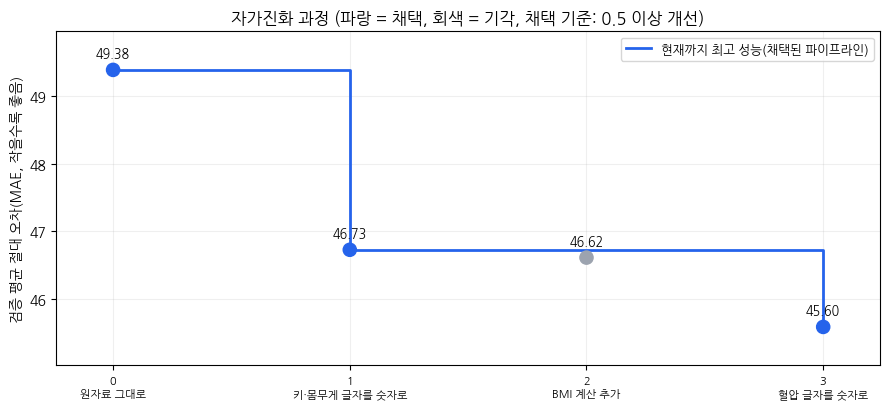

채택된 처리 단계: 키·몸무게 글자를 숫자로 → 혈압 글자를 숫자로


In [6]:
# ④ 제안 → 실행 → 평가 → 채택/기각
kept_steps, history = self_evolve(PROPOSALS, MIN_IMPROVEMENT)
display(history.round(2))
plot_history(history, MIN_IMPROVEMENT)
print("채택된 처리 단계:", " → ".join(name for name, _ in kept_steps) or "없음(원자료 그대로)")
steps_after_4 = list(kept_steps)  # ⑤에서 '④에서 채택된 결과에 이어서'를 고를 때 씁니다.

**결과 읽기**
- 글자를 숫자로 바꾸자 오차가 크게 줄었습니다. Kumo는 글자 칸을 "범주"로만 볼 수 있어서 키·몸무게·혈압의 크기를 쓰지 못했기 때문입니다.
- BMI 계산은 이미 키·몸무게가 있으니 새 정보가 거의 없어서, 개선 폭이 기준보다 작아 **기각**되었습니다. 좋아 보이는 아이디어도 **검증해서 좋아지지 않으면 채택하지 않는 것**이 자가진화의 핵심입니다.
- **기각이 곧 '효과 없음'은 아닙니다.** 검증 환자가 89명뿐이라 작지만 진짜인 효과는 우연한 흔들림에 묻혀 기각될 수 있습니다. 제작 중 자료를 100번 새로 나눠 반복해 보니, "혈압 글자를 숫자로"는 55번만 채택됐지만 시험 자료에서는 91번 오차를 줄였습니다. 반대로 우연히 좋아 보인 제안이 채택되기도 합니다. 그래서 채택 기준을 미리 정하고, 마지막에 시험 자료로 한 번 더 확인합니다.

## ⑤ AI 에이전트에게 맡겨 보기 (진짜 자가진화)

④에서는 제안을 미리 적어 두었습니다. 이번에는 **AI가 직접 제안**합니다. 한 라운드는 이렇게 돌아갑니다.
1. **제안**: AI가 표의 열 이름·예시값과 지금까지의 점수·오류를 보고 처리 함수 `my_proposal(x)`를 씁니다.
2. **안전 검사**: 파일·인터넷 접근, 정답(target) 엿보기, 너무 오래 걸리는 코드는 걸러냅니다.
3. **실행·평가**: 검증 환자 89명에서 오차(MAE)를 잽니다.
4. **채택/기각**: ④와 같은 기준(`MIN_IMPROVEMENT`)으로 정합니다.
5. **피드백**: 점수와 오류 메시지를 AI에게 알려 주고 다음 라운드로 갑니다.

- **AI 연결**: Colab에 로그인했다면 **키 없이 무료**로 Colab AI(Gemini)를 씁니다(만 18세 이상 계정). 안 되면 OpenRouter(설정 셀의 키 칸 또는 왼쪽 🔑 보안 비밀 `OPENROUTER_API_KEY`, 모델은 GLM 5.3 Flash)를, 둘 다 없으면 **미리 준비한 후보**를 씁니다. 그래서 셀은 항상 끝까지 실행됩니다. 각 라운드의 `[Colab AI]`, `[OpenRouter]`, `[오프라인 후보]` 표시로 어느 쪽을 썼는지 알 수 있습니다.
- AI는 같은 질문에도 매번 다른 답을 냅니다. 옆 사람과 결과가 달라도 정상입니다.
- **힌트** 칸에 `혈압 열을 살펴봐`처럼 적어 AI를 이끌어 보세요. 연구자가 방향을 주고, AI가 코드를 쓰고, 검증 자료가 판정합니다.
- 내 데이터를 쓸 때(`USE_MY_DATA` 체크)는 열 이름과 자료형만 AI에게 보내고 **값은 보내지 않습니다**.

In [7]:
#@title 🔧 ⑤ AI 에이전트 도구 불러오기 (실행만 하세요)
# ==== 실습 4 ⑤ "AI 에이전트가 직접 제안하는 자가진화" 도구 함수 (숨김 셀에 붙여 넣기) ====
# 필요한 전역: data, validation_mae, apply_steps, features_of, plot_history (실습 4 도구 셀), pd, np
import ast, contextlib, math, os, re, signal, textwrap, threading

OPENROUTER_MODEL = "z-ai/glm-5.3-flash"  # 2026-10 기준 저렴·빠름·종합 지능 지수 상위(입력 $0.004, 출력 $0.134 / 100만 토큰)
COLAB_MODEL = ""                       # 비워 두면 Colab AI 기본 모델(현재 Gemini Flash 계열)
EXEC_TIMEOUT = 10                      # 제안 코드 1회 실행 제한 시간(초)
MAX_COLUMNS = 60


class ProposalError(Exception):
    """제안 코드가 규칙을 어기거나 실행에 실패했을 때."""


class ProposalTimeout(BaseException):
    """BaseException이라 제안 코드 안의 except Exception 으로는 잡히지 않습니다."""


class LLMUnavailable(Exception):
    """AI 서비스에 연결할 수 없을 때(Colab 밖, 키 없음, 사용 한도 초과 등)."""


# ---------------------------------------------------------------- 1) 안전 검사 + 제한된 실행
_ALLOWED_MODULES = {"pandas", "numpy", "re", "math"}
_FORBIDDEN_NAMES = {"eval", "exec", "compile", "open", "globals", "locals", "vars", "getattr", "setattr",
                    "delattr", "input", "breakpoint", "exit", "quit", "help", "memoryview", "__import__",
                    "type", "object", "super", "classmethod", "staticmethod", "property"}
_FORBIDDEN_ATTRS = {"eval", "query", "system", "popen", "load", "loads", "save", "savez", "savez_compressed",
                    "savetxt", "loadtxt", "genfromtxt", "fromfile", "tofile", "memmap", "ctypeslib", "lib",
                    "f2py", "testing", "io", "os", "sys", "subprocess", "core", "util", "compat", "plotting",
                    "options", "set_option", "pipe", "dump", "dumps", "fromregex", "DataSource", "ExcelWriter",
                    "ExcelFile", "HDFStore"}
_ALLOWED_TO = {"to_numeric", "to_datetime", "to_timedelta", "to_numpy", "to_list", "to_dict", "to_frame",
               "to_string", "to_period"}
_SAFE_BUILTIN_NAMES = ["abs", "all", "any", "bool", "dict", "enumerate", "filter", "float", "int", "isinstance",
                       "len", "list", "map", "max", "min", "print", "range", "reversed", "round", "set", "slice",
                       "sorted", "str", "sum", "tuple", "zip", "Exception", "ValueError", "KeyError", "TypeError",
                       "IndexError", "ZeroDivisionError", "AttributeError"]


def _safe_import(name, globals=None, locals=None, fromlist=(), level=0):
    if level or name not in _ALLOWED_MODULES:
        raise ProposalError(f"'{name}' 모듈은 쓸 수 없습니다(pandas·numpy·re·math만 가능)")
    return __import__(name)


_bi = __builtins__ if isinstance(__builtins__, dict) else vars(__builtins__)
_SAFE_BUILTINS = {k: _bi[k] for k in _SAFE_BUILTIN_NAMES}
_SAFE_BUILTINS["__import__"] = _safe_import


def check_code(code):
    """실행 전에 코드를 읽어서 금지된 것이 있는지 봅니다. 문제 목록(한국어)을 돌려줍니다."""
    if len(code) > 5000:
        return ["코드가 너무 깁니다(5000자 이하)"]
    try:
        tree = ast.parse(code)
    except SyntaxError as e:
        return [f"문법 오류(줄 {e.lineno}): {e.msg}"]
    problems = []
    if not any(isinstance(n, ast.FunctionDef) and n.name == "my_proposal" for n in tree.body):
        problems.append("def my_proposal(x): 함수가 없습니다")
    for n in tree.body:
        if not isinstance(n, (ast.FunctionDef, ast.Import, ast.ImportFrom, ast.Assign, ast.Expr)):
            problems.append(f"함수 밖에는 정의·import만 둘 수 있습니다(줄 {n.lineno})")
    for n in ast.walk(tree):
        if isinstance(n, ast.Import):
            bad = [a.name for a in n.names if a.name not in _ALLOWED_MODULES]
            if bad:
                problems.append(f"import {', '.join(bad)} 금지(pandas·numpy·re·math만 가능)")
        elif isinstance(n, ast.ImportFrom):
            if n.module not in _ALLOWED_MODULES or any(a.name in _FORBIDDEN_ATTRS or a.name.startswith(("_", "read_"))
                                                       for a in n.names):
                problems.append(f"from {n.module} import ... 금지")
        elif isinstance(n, ast.Name) and n.id in _FORBIDDEN_NAMES:
            problems.append(f"'{n.id}' 사용 금지")
        elif isinstance(n, ast.Attribute):
            a = n.attr
            if a.startswith("_") or a in _FORBIDDEN_ATTRS or a.startswith("read_") or (
                    a.startswith("to_") and a not in _ALLOWED_TO):
                problems.append(f"'.{a}' 사용 금지(파일·시스템 접근 또는 내부 속성)")
        elif isinstance(n, (ast.While, ast.ClassDef, ast.Global, ast.Nonlocal, ast.AsyncFunctionDef)):
            problems.append(f"{type(n).__name__} 문법은 쓸 수 없습니다")
        elif isinstance(n, ast.ExceptHandler) and (n.type is None or getattr(n.type, "id", "") == "BaseException"):
            problems.append("except: / except BaseException: 은 쓸 수 없습니다(except Exception: 사용)")
    return sorted(set(problems), key=problems.index)


@contextlib.contextmanager
def time_limit(seconds):
    """파이썬 코드가 seconds초를 넘기면 멈춥니다(Colab/리눅스 메인 스레드에서 작동)."""
    if not hasattr(signal, "SIGALRM") or threading.current_thread() is not threading.main_thread():
        yield
        return

    def _raise(signum, frame):
        raise ProposalTimeout(f"{seconds}초 안에 끝나지 않았습니다")

    old = signal.signal(signal.SIGALRM, _raise)
    signal.setitimer(signal.ITIMER_REAL, seconds)
    try:
        yield
    finally:
        signal.setitimer(signal.ITIMER_REAL, 0)
        signal.signal(signal.SIGALRM, old)


def build_step(code):
    """검사를 통과한 코드를 제한된 이름 공간(pd, np, re, math만 있음)에서 실행해 처리 단계 함수를 만듭니다.
    data·target·split 같은 노트북 변수는 이 공간에 없어서 제안 코드가 정답을 몰래 볼 수 없습니다."""
    problems = check_code(code)
    if problems:
        raise ProposalError("안전 검사 탈락: " + "; ".join(problems))
    env = {"__builtins__": _SAFE_BUILTINS, "pd": pd, "np": np, "re": re, "math": math}
    with time_limit(EXEC_TIMEOUT):
        exec(compile(code, "<AI 제안>", "exec"), env)
    fn = env["my_proposal"]

    def step(x):
        n, idx = len(x), x.index
        with time_limit(EXEC_TIMEOUT):
            out = fn(x)
        if out is None:
            raise ProposalError("함수가 표를 돌려주지 않았습니다(마지막 줄에 return x 필요)")
        if not isinstance(out, pd.DataFrame):
            raise ProposalError(f"표(DataFrame)가 아니라 {type(out).__name__}을(를) 돌려주었습니다")
        if len(out) != n or not out.index.equals(idx):
            raise ProposalError("행 수나 순서가 바뀌었습니다(행을 지우거나 정렬하면 안 됩니다)")
        if {"target", "split"} & set(map(str, out.columns)):
            raise ProposalError("target/split 열은 만들 수 없습니다")
        if out.columns.duplicated().any():
            raise ProposalError("같은 이름의 열이 두 개 있습니다")
        if not 0 < out.shape[1] <= MAX_COLUMNS:
            raise ProposalError(f"열 개수가 {out.shape[1]}개입니다(1~{MAX_COLUMNS}개만 가능)")
        out = out.replace([np.inf, -np.inf], np.nan)
        for c in out.columns:
            if out[c].dtype == bool:
                out[c] = out[c].astype(float)
        return out

    return step


def check_consistency(steps):
    """학습·검증·시험 자료에 따로 적용해도, 전체에 한 번에 적용했을 때와 결과가 같아야 합니다.
    (예: 자료 묶음마다 평균·분위수·치우침을 따로 계산하면 학습과 검증의 기준이 달라져 점수가 가짜로 좋아질 수 있음)
    정답(target) 열은 쓰지 않습니다."""
    full = apply_steps(features_of(data), steps)
    for part, label in [("train", "학습"), ("validation", "검증"), ("test", "시험")]:
        sub = apply_steps(features_of(data[data["split"] == part]), steps)
        if list(sub.columns) != list(full.columns):
            raise ProposalError(f"{label} 자료에서 만들어진 열이 전체 자료와 다릅니다(pd.get_dummies 등 대신 숫자로 바꾸기)")
        ref = full.loc[sub.index]
        for c in sub.columns:
            a, b = sub[c], ref[c]
            if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
                same = np.allclose(a.to_numpy(float), b.to_numpy(float), rtol=1e-6, atol=1e-9, equal_nan=True)
            else:
                same = a.astype(str).equals(b.astype(str))
            if not same:
                raise ProposalError(f"'{c}' 열 값이 자료 묶음({label})마다 다르게 계산됩니다. 평균·분위수·치우침처럼 "
                                    "여러 행을 모아 계산하는 처리 대신, 각 환자 행만 보고 계산하는 처리를 쓰세요")


def idea_of(code):
    """함수 첫 줄 설명(docstring)을 아이디어 요약으로 씁니다."""
    try:
        for n in ast.parse(code).body:
            if isinstance(n, ast.FunctionDef) and n.name == "my_proposal":
                doc = ast.get_docstring(n)
                if doc:
                    return doc.strip().splitlines()[0][:80]
    except SyntaxError:
        pass
    return "(설명 없음)"


def explain_error(e):
    if isinstance(e, KeyError):
        return f"없는 열 이름을 썼습니다: {e}"
    if isinstance(e, NameError):
        return f"정의되지 않은 이름을 썼습니다: {e} (쓸 수 있는 것은 x, pd, np, re, math뿐)"
    if isinstance(e, (ProposalError, ProposalTimeout)):
        return str(e)
    return f"{type(e).__name__}: {str(e)[:200]}"


# ---------------------------------------------------------------- 2) AI에게 보낼 자료 설명과 질문
def make_columns_preview(steps, n_examples=3):
    """현재(채택된 처리를 적용한 뒤) 표의 열 이름·종류·예시값. 내 데이터 모드에서는 값을 보내지 않습니다."""
    send_values = not globals().get("USE_MY_DATA", False)
    x = apply_steps(features_of(data[data["split"] == "train"]), steps)
    lines = []
    for c in x.columns:
        s = x[c]
        kind = "숫자" if pd.api.types.is_numeric_dtype(s) else "글자"
        ex = (", ".join(repr(v) if isinstance(v, str) else f"{v:g}" for v in s.dropna().unique()[:n_examples])
              if send_values else "(값은 보내지 않음)")
        label = globals().get("COLUMN_NAMES", {}).get(c, "") if not globals().get("USE_MY_DATA") else ""
        lines.append(f"- {c}{' = ' + label if label else ''} ({kind}, 서로 다른 값 {s.nunique()}개, "
                     f"빈칸 {int(s.isna().sum())}개) 예: {ex}")
    return "\n".join(lines)


def build_prompt(feedback_history, columns_preview, hint=""):
    target = globals().get("TARGET_COLUMN", "target") if globals().get("USE_MY_DATA") else "1년 뒤 당뇨병 진행 점수"
    past = "\n".join(
        f"{i}) 아이디어: {f['idea']}\n   결과: {f['result']}\n   코드:\n" + textwrap.indent(f["code"][:800], "      ")
        for i, f in enumerate(feedback_history, 1)) or "(아직 없음)"
    return f"""당신은 의료 데이터 전처리를 돕는 AI 에이전트입니다.
환자 1명이 1행인 pandas 표 `x`를 받아 고친 표를 돌려주는 파이썬 함수 `my_proposal(x)`를 하나 제안하세요.

[목표] 예측 모델(Kumo, 바꿀 수 없음)이 '{target}'(숫자)을 더 정확히 예측하도록 표를 고칩니다.
평가는 검증 환자의 평균 절대 오차(MAE)이며, 작을수록 좋습니다. 모델은 글자 열을 범주로만 보고 크기는 모릅니다.

[현재 표의 열] (지금까지 채택된 처리가 이미 적용된 모습)
{columns_preview}

[이전 시도와 결과] 같은 아이디어는 반복하지 말고, 오류가 났다면 원인을 고쳐 다시 제안하세요.
{past}

[연구자의 힌트] {hint or "(없음)"}

[규칙]
1. 답에는 ```python 코드 블록 하나만 넣으세요. 그 안에 def my_proposal(x): 를 정의하고 마지막에 return x 하세요.
2. 함수 첫 줄에 아이디어를 한국어 한 문장 docstring으로 쓰세요.
3. pandas(pd), numpy(np), re, math만 쓰세요. 파일·인터넷·시스템 접근, while 문, 다른 import는 금지입니다.
4. 행을 지우거나 순서를 바꾸지 마세요. 열을 추가·변환·삭제하는 것은 괜찮습니다.
5. 표에는 예측 대상(target)과 자료 구분(split) 열이 없습니다. 만들지도 마세요.
6. 함수는 학습·검증·시험 자료에 따로 적용됩니다. 그래서 각 환자 행만 보고 계산하세요.
   평균·표준편차·분위수(qcut)·pd.get_dummies처럼 여러 행을 모아 계산하는 처리는 기각됩니다.
7. 한 번에 아이디어 하나만 제안하세요.
"""


def extract_code(text):
    if not text or not text.strip():
        raise ProposalError("AI가 빈 답을 보냈습니다")
    blocks = re.findall(r"```(?:python|py)?[ \t]*\n(.*?)(?:```|$)", text, flags=re.S)
    for b in blocks:
        if "def my_proposal" in b:
            return b.strip()
    if "def my_proposal" in text:
        return text[text.index("def my_proposal"):].strip()
    raise ProposalError("AI 답에서 def my_proposal(x) 코드를 찾지 못했습니다")


# ---------------------------------------------------------------- 3) AI 연결 (Colab AI → OpenRouter → 오프라인)
def _secret(name):
    """설정 셀에 적은 값 → Colab 보안 비밀(🔑) → 환경변수 순서로 찾습니다."""
    typed = str(globals().get(name, "") or "").strip()
    if typed:
        return typed
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    return os.environ.get(name, "")


def _ask_colab(prompt):
    try:
        from google.colab import ai
    except Exception:
        raise LLMUnavailable("Colab 밖이거나 Colab AI를 쓸 수 없는 계정입니다(만 18세 이상·지원 지역 필요)")
    global COLAB_MODEL
    try:
        return ai.generate_text(prompt, **({"model_name": COLAB_MODEL} if COLAB_MODEL else {}))
    except Exception as e:
        msg = str(e)
        if "429" in msg or "quota" in msg.lower():
            raise LLMUnavailable("Colab AI 사용 한도를 넘었습니다(잠시 뒤 또는 내일 다시)")
        if not COLAB_MODEL:  # 기본 모델 이름이 바뀌었거나 무료 계정에 없을 때: 쓸 수 있는 Flash 모델로 한 번 더
            try:
                flash = [m for m in ai.list_models() if "flash" in m]
                if flash:
                    COLAB_MODEL = flash[-1]
                    print(f"   (Colab AI 기본 모델 대신 {COLAB_MODEL} 사용)")
                    return ai.generate_text(prompt, model_name=COLAB_MODEL)
            except Exception:
                pass
        raise LLMUnavailable(f"Colab AI 오류: {msg[:150]}")


def _ask_openrouter(prompt):
    import requests
    key = _secret("OPENROUTER_API_KEY")
    if not key:
        raise LLMUnavailable("OpenRouter 키가 없습니다(설정 셀의 OPENROUTER_API_KEY 칸 또는 왼쪽 🔑 보안 비밀)")
    payload = {"model": OPENROUTER_MODEL, "max_tokens": 8000,
               "messages": [{"role": "user", "content": prompt}],
               "reasoning": {"effort": "low"}}  # 추론 모델이 오래 생각하지 않도록(빠르고 저렴하게)
    try:
        r = requests.post("https://openrouter.ai/api/v1/chat/completions", timeout=120,
                          headers={"Authorization": f"Bearer {key}"}, json=payload)
        if r.status_code == 400 and "reasoning" in r.text.lower():  # 추론 옵션을 받지 않는 모델이면 빼고 다시
            payload.pop("reasoning")
            r = requests.post("https://openrouter.ai/api/v1/chat/completions", timeout=120,
                              headers={"Authorization": f"Bearer {key}"}, json=payload)
    except Exception as e:
        raise LLMUnavailable(f"OpenRouter 연결 실패: {type(e).__name__}")
    reasons = {401: "키가 잘못되었습니다", 402: "크레딧이 부족합니다", 429: "요청이 너무 많습니다(잠시 뒤 다시)"}
    if r.status_code != 200:
        raise LLMUnavailable(f"OpenRouter {r.status_code}: {reasons.get(r.status_code, r.text[:150])}")
    return r.json()["choices"][0]["message"]["content"] or ""


OFFLINE_CANDIDATES = [  # AI 없이도 실습이 돌아가도록 미리 준비한 후보(순서대로 시도)
    '''def my_proposal(x):
    """글자 칸 안의 숫자를 꺼내 숫자 열로 바꿉니다(예: '170.2cm 72.5kg' → 170.2, 72.5)."""
    for col in [c for c in x.columns if not pd.api.types.is_numeric_dtype(x[c])]:
        nums = x[col].astype(str).str.findall(r"-?\\d+\\.?\\d*")
        k = int(nums.str.len().median())
        if k >= 1:
            for i in range(k):
                x[f"{col}_num{i + 1}"] = nums.map(lambda v: float(v[i]) if len(v) > i else np.nan)
            x = x.drop(columns=col)
    return x''',
    '''def my_proposal(x):
    """키(cm)와 몸무게(kg)로 BMI를 계산해 추가합니다."""
    x["bmi"] = x["body_num2"] / (x["body_num1"] / 100) ** 2
    return x''',
    '''def my_proposal(x):
    """LDL을 HDL로 나눈 비율을 추가합니다."""
    x["ldl_hdl"] = x["s2"] / x["s3"]
    return x''',
]
for _c in OFFLINE_CANDIDATES:  # 미리 준비한 후보도 같은 안전 검사를 통과해야 합니다
    assert not check_code(_c), check_code(_c)


def _offline(feedback_history):
    tried = {f["idea"] for f in feedback_history}
    for c in OFFLINE_CANDIDATES:
        if idea_of(c) not in tried:
            return "```python\n" + c + "\n```"
    raise LLMUnavailable("미리 준비한 후보를 모두 시도했습니다")


LLM_BACKENDS = {"colab": ("Colab AI", _ask_colab), "openrouter": ("OpenRouter", _ask_openrouter)}
SOURCE_ROUTES = {"자동": ["colab", "openrouter"], "Colab AI (무료, 키 없음)": ["colab"],
                 "OpenRouter (키 필요)": ["openrouter"], "오프라인 (AI 없이)": []}
_DEAD = {}  # 이번 실행에서 연결이 안 된 AI는 다시 부르지 않습니다


def llm_propose(feedback_history, columns_preview, hint="", source="자동"):
    """AI에게 제안을 받아 파이썬 코드 문자열(def my_proposal...)을 돌려줍니다.
    AI를 쓸 수 없으면 미리 준비한 후보로 대신합니다. 어디서 왔는지는 llm_propose.last_source에 남깁니다."""
    prompt = build_prompt(feedback_history, columns_preview, hint)
    llm_propose.last_prompt = prompt
    for key in SOURCE_ROUTES.get(source, [source]):
        label, ask = LLM_BACKENDS[key]
        if key in _DEAD:
            continue
        try:
            text = ask(prompt)
            llm_propose.last_source = label
            return extract_code(text)
        except LLMUnavailable as e:
            _DEAD[key] = str(e)
            print(f"   ⚠️ {label} 사용 불가: {e}")
    llm_propose.last_source = "오프라인 후보"
    return extract_code(_offline(feedback_history))


# ---------------------------------------------------------------- 4) 자가진화 반복
def _short(text, n=16):
    return text if len(text) <= n else text[:n] + "…"


def ai_self_evolve(rounds=3, min_improvement=0.5, source="자동", hint="", start_steps=(), show_code=True):
    """AI 제안 → 안전 검사 → 실행 → 검증 평가 → 채택/기각 → 결과를 AI에게 알려 주기, 를 rounds번 반복합니다."""
    _DEAD.clear()
    kept = list(start_steps)
    best = validation_mae(kept)
    start_name = "원자료 그대로" if not kept else "④ 결과에서 시작"
    rows = [{"단계": 0, "출처": "-", "제안": start_name, "검증 MAE": best, "변화": 0.0, "결정": "출발점", "메모": "",
             "아이디어": start_name, "코드": ""}]
    feedback = []
    print(f"[0] {start_name} → 검증 MAE {best:.2f}  (채택 기준: {min_improvement} 이상 감소)")
    for r in range(1, rounds + 1):
        print(f"\n━━━ 라운드 {r}/{rounds} ━━━")
        code, src = "", "-"
        try:
            code = llm_propose(feedback, make_columns_preview(kept), hint=hint, source=source)
            src = llm_propose.last_source
            idea = idea_of(code)
            print(f"💡 [{src}] {idea}")
            if show_code:
                print(textwrap.indent("\n".join(code.splitlines()[:25]), "   │ "))
            step = build_step(code)
            name = _short(idea, 12)
            check_consistency(kept + [(name, step)])
            score = validation_mae(kept + [(name, step)])
        except LLMUnavailable as e:
            print(f"⏹ 더 제안을 받을 수 없어 멈춥니다: {e}")
            break
        except (Exception, ProposalTimeout) as e:
            src = getattr(llm_propose, "last_source", "-")
            idea = idea_of(code) if code else "(코드 없음)"
            msg = explain_error(e)
            print(f"❌ 기각(오류): {msg}\n   → 오류 내용을 AI에게 알려 주고 다음 라운드에서 고치게 합니다.")
            rows.append({"단계": r, "출처": src, "제안": _short(idea, 12), "검증 MAE": np.nan, "변화": np.nan,
                         "결정": "기각(오류)", "메모": msg, "아이디어": idea, "코드": code})
            feedback.append({"idea": idea, "code": code or "(없음)", "result": f"오류로 기각: {msg}"})
            continue
        gain = best - score
        accepted = gain >= min_improvement
        decision = "✅ 채택" if accepted else ("기각(변화 없음)" if abs(gain) < 1e-9 else
                                              "기각(개선 폭이 작음)" if gain > 0 else "기각(나빠짐)")
        print(f"📏 검증 MAE {best:.2f} → {score:.2f} ({-gain:+.2f}) {decision}")
        rows.append({"단계": r, "출처": src, "제안": name, "검증 MAE": score, "변화": -gain, "결정": decision, "메모": "",
                     "아이디어": idea, "코드": code})
        feedback.append({"idea": idea, "code": code,
                         "result": f"검증 MAE {best:.2f} → {score:.2f} ({-gain:+.2f}), {decision}"
                                   + (" (이 처리는 이제 표에 적용되어 있음)" if accepted else "")})
        if accepted:
            kept.append((name, step))
            best = score
    ai_self_evolve.feedback = feedback
    return kept, pd.DataFrame(rows)

print("✅ AI 에이전트 도구 준비 완료")

✅ AI 에이전트 도구 준비 완료


In [8]:
#@title ⚙️ ⑤ AI 에이전트 자가진화 설정
#@markdown **AI 연결**: "자동"은 Colab AI(무료·키 없음)를 먼저 쓰고, 안 되면 OpenRouter, 그것도 안 되면 미리 준비한 후보로 진행합니다. OpenRouter로만 하려면 "OpenRouter (키 필요)"를 고르세요(모델: GLM 5.3 Flash, 라운드당 1센트 미만).
AI_SOURCE = "OpenRouter (키 필요)"
#@markdown **OpenRouter 키**: 실습 5와 **같은 키**입니다. 왼쪽 🔑 보안 비밀에 `OPENROUTER_API_KEY`로 한 번 넣어 두면 두 실습 모두 칸을 비워 둬도 됩니다. ⚠️ 이 칸에 적은 키는 노트북 파일에 함께 저장되니, 노트북을 공유하기 전에 꼭 지우세요.
OPENROUTER_API_KEY = ""  #@param {type:"string"}
ROUNDS = 3  #@param {type:"slider", min:1, max:6, step:1}
#@markdown **힌트(선택)**: AI에게 방향을 알려 주세요. 예) `혈압 열을 살펴봐`, `나이와 성별을 함께 써 봐`
HINT = ""  #@param {type:"string"}
START_FROM = "원자료부터"  #@param ["원자료부터", "④에서 채택된 결과에 이어서"]
SHOW_CODE = True  #@param {type:"boolean"}

[0] 원자료 그대로 → 검증 MAE 49.38  (채택 기준: 0.5 이상 감소)

━━━ 라운드 1/3 ━━━
💡 [OpenRouter] body에서 키·몸무게·BMI를 숫자 열로, bp_text에서 수축기 혈압을 숫자 열로 추출한다.
   │ def my_proposal(x):
   │     """body에서 키·몸무게·BMI를 숫자 열로, bp_text에서 수축기 혈압을 숫자 열로 추출한다."""
   │     x = x.copy()
   │     m = x['body'].str.extract(r'(?P<height>[\d.]+)\s*cm\s*(?P<weight>[\d.]+)\s*kg')
   │     x['height'] = pd.to_numeric(m['height'], errors='coerce')
   │     x['weight'] = pd.to_numeric(m['weight'], errors='coerce')
   │     x['bmi'] = x['weight'] / (x['height'] / 100) ** 2
   │     x['bp'] = pd.to_numeric(x['bp_text'].str.extract(r'(?P<v>[\d.]+)')[0], errors='coerce')
   │     x['bmi_x_bp'] = x['bmi'] * x['bp']
   │     x = x.drop(columns=['body', 'bp_text'])
   │     return x
❌ 기각(오류): 없는 열 이름을 썼습니다: 0
   → 오류 내용을 AI에게 알려 주고 다음 라운드에서 고치게 합니다.

━━━ 라운드 2/3 ━━━
💡 [OpenRouter] body에서 키·몸무게·BMI를, bp_text에서 수축기 혈압을 숫자 열로 추출해 추가한다.
   │ def my_proposal(x):
   │     """body에서 키·몸무게·BMI를, bp_text에서 수축기 혈압을 숫자 열로 추출해 추가한다."""
   │     x = 

,단계,출처,제안,검증 MAE,변화,결정,메모
0,0,-,원자료 그대로,49.38,0.00,출발점,
1,1,OpenRouter,body에서 키·몸무게…,NaN,NaN,기각(오류),없는 열 이름을 썼습니다: 0
2,2,OpenRouter,body에서 키·몸무게…,45.65,-3.72,✅ 채택,
3,3,OpenRouter,행별로 파생 특성(bm…,45.68,0.03,기각(나빠짐),


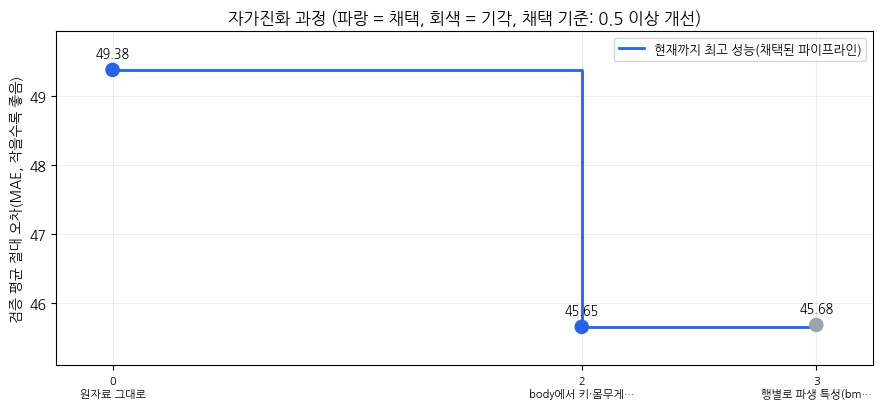

채택된 처리 단계: body에서 키·몸무게…


In [9]:
# ⑤ AI 에이전트 자가진화: 제안 → 안전 검사 → 실행 → 검증 평가 → 채택/기각 → 결과를 AI에게 알려 주기
start = steps_after_4 if START_FROM.startswith("④") else []
kept_steps, history = ai_self_evolve(ROUNDS, MIN_IMPROVEMENT, AI_SOURCE, HINT, start, SHOW_CODE)
display(history.drop(columns=["아이디어", "코드"]).round(2))
plot_history(history, MIN_IMPROVEMENT)
print("채택된 처리 단계:", " → ".join(name for name, _ in kept_steps) or "없음(원자료 그대로)")

**결과 읽기**: AI가 각 라운드에서 쓴 코드는 `print(history.loc[1, "코드"])`처럼 볼 수 있습니다. 라운드를 늘릴수록 검증 자료에 우연히 맞춘 제안이 채택될 위험도 커집니다. 그래서 라운드는 최대 6번으로 제한했고, 마지막 ⑥에서 시험 자료로 **한 번만** 확인합니다.

## ⑥ 마지막 확인: 시험 자료로 한 번만 평가

제안 채택이 모두 끝난 뒤 실행합니다. ⑤를 실행했다면 ⑤에서 채택된 처리로, 실행하지 않았다면 ④의 결과로 확인합니다. **시험 결과를 본 뒤에는 제안을 다시 고르지 않습니다.** 시험 자료가 더 이상 "처음 보는 자료"가 아니게 되기 때문입니다.

In [10]:
#@title ⚙️ ⑥ 시험 자료로 최종 확인
RUN_FINAL_TEST = True  #@param {type:"boolean"}
if RUN_FINAL_TEST:
    train, test_set = data[data["split"] == "train"], data[data["split"] == "test"]
    rows = []
    for label, steps in [("원자료 그대로", []), ("자가진화 후", kept_steps)]:
        pred = kumo_predict(apply_steps(features_of(train), steps), train["target"], apply_steps(features_of(test_set), steps))
        rows.append({"파이프라인": label, "시험 MAE": mean_absolute_error(test_set["target"], pred)})
    final = pd.DataFrame(rows).round(2)
    display(final)
    before, after = final["시험 MAE"]
    display(Markdown(f"**해석**: 처음 보는 시험 환자 {len(test_set)}명에서도 오차가 **{before:.1f} → {after:.1f}**"
                     + (f"로 **{(1 - after / before) * 100:.0f}%** 줄었습니다." if after < before else "로 줄지 않았습니다.")))

,파이프라인,시험 MAE
0,원자료 그대로,54.98
1,자가진화 후,48.47


**해석**: 처음 보는 시험 환자 89명에서도 오차가 **55.0 → 48.5**로 **12%** 줄었습니다.